# Engineering design with Python: optimize a cylindrical tank
### A guided case study for independent study

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 07 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/07_Engineering_Design_Optimization.ipynb)

**Engineering question.** A closed cylindrical tank must hold a specified volume. How should we choose its radius and height to use the least sheet material? We will turn that question into a function, search candidate designs with Python, check the result by algebra, and then impose a practical height limit and a short list of available radii.

This is a **self-study case study**. Its notebook format (`.ipynb`) is for studying explanations alongside runnable cells. The core path needs only basic algebra and the programming ideas of notebooks 01–04. Later algorithms and an object-oriented representation are clearly marked **optional**.

### How to work through the notebook

1. Read each model statement and predict the output before running its code cell. Check units and small examples by hand.
2. Run cells from top to bottom. Read the comment next to each executable line; comments explain the reason for each calculation, check, and loop boundary.
3. Change one assumption or input in a copy of the notebook and rerun from the relevant cell. If an assertion fails, inspect the equation and units before changing the tolerance.
4. Attempt the questions near the end, then compare your answers with the worked checks.

**Learning goals.** Translate an engineering objective into code; distinguish design variables, fixed parameters, and constraints; use loops, `if`, lists, functions, and tuples to search designs; interpret numerical convergence and operation counts; test both code and the physical model; and explain why a numerical optimum is approximate.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 2, Collections and data |
| **Time** | about 35 min (about 70 min with exercises) |
| **Before this** | Notebooks 01–02 (functions, loops, `if`); notebook 05 for the NumPy used in the figures. |
| **Essential** | Sections 1–6, 9 and 10. |
| **Optional on a first reading** | Section 7 (golden-section search) and Section 8 (a design as an object, previewing notebook 10). |
| **Next** | 08, Find the bugs. |

**You have understood this notebook if you can, without looking back:**

1. Write the steel area of a closed tank as a function of radius, using the volume requirement to eliminate the height.
2. Find the best radius on a grid with a `for` loop, an `if` test and a running best value, and wrap the search in a reusable function.
3. Check the numerical answer against the analytic optimum h = 2r, and explain why the two agree only to the grid spacing.
4. Estimate how many evaluations a finer grid needs for one more correct digit.
5. Add a practical constraint (a height limit, or only certain radii available) and explain why the best design changes.

**Not expected of you:** The calculus check in Section 4: read it, but you do not have to reproduce it.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## Reading map: Python ideas used here

| Step in this case study | Python ideas |
|:--|:--|
| Define volume, radius, height, and material area | Variables, `float`, arithmetic, `math.pi`, units, functions and `return` |
| Search a grid of candidate radii | `range`, lists, `for`, `if`, state updates, zero-based indices |
| Check and refine a result | Floating-point tolerances, tests, exceptions, decomposition |
| Compare search resolutions | Operation counts and growth with input size |
| Restrict designs by height and available sizes | Lists, tuples, dictionaries, conditions, `None` |
| Draw figures and use numerical arrays | NumPy, Matplotlib and engineering interpretation |
| Optional search and class | Bounded `while`, algorithm design, `class`, methods and instances |

The core search uses plain Python loops before introducing compact library operations. The physical formula is simple enough to verify independently, which lets us ask whether a program solved the *intended engineering problem*, not merely whether it ran without errors.

In [1]:
# Import the standard math module for pi, square roots, and finite-value checks.
import math
# Import NumPy for evenly spaced plotting coordinates and numerical comparisons.
import numpy as np
# Import Matplotlib for objective, search-error, and constrained-design figures.
import matplotlib.pyplot as plt
# Set a readable size for all figures embedded in the notebook.
plt.rcParams['figure.figsize'] = (7.4, 4.2)
# Choose a tolerance for numerical checks whose exact mathematical value is known.
check_tolerance = 1e-10
# Display the numerical package version so the computing environment is identifiable.
print('NumPy version:', np.__version__)

NumPy version: 2.5.3


## 1. Translate the engineering question into a function

Let $V$ be the tank's required *internal* volume in cubic metres, $r$ its internal radius in metres, and $h$ its internal height in metres. For a cylinder,

$$V=\pi r^2h \quad\Longrightarrow\quad h(r)=\frac{V}{\pi r^2}.$$

A **closed** cylinder has two circular ends and one curved wall. If we idealize the sheet as having uniform thickness and neglect seams, supports, and wastage, its material requirement is proportional to its total surface area:

$$S=2\pi r^2+2\pi rh
  =2\pi r^2+\frac{2V}{r}.$$

The radius is our **design variable**; $V$ is a fixed **parameter**; $h$ follows from the volume requirement. Both terms in $S$ have units of square metres. A very small radius makes the tank tall and its wall large; a very large radius makes its two ends large. We expect an interior minimum. A real design may need different prices for walls and ends, material thickness, safety factors, and manufacturing constraints; this simplified model teaches the computational method.

We use $V=1.0\,\mathrm{m^3}$ in the worked example. A radius of zero or negative volume has no physical meaning, so our functions reject it explicitly.

In [2]:
# Define a function that converts a radius and required volume into a height.
def height_for_radius(volume, radius):
    # Document input units and the physical output of the calculation.
    """Return a cylinder height in m for positive volume (m³) and radius (m)."""
    # Reject non-finite, zero, and negative numerical inputs before division.
    if not math.isfinite(volume) or not math.isfinite(radius) or volume <= 0.0 or radius <= 0.0:
        # Give the caller a useful explanation rather than a division-by-zero result.
        raise ValueError('volume and radius must be finite positive numbers')
    # Rearrange V = pi*r**2*h; pi*r**2 is the cross-sectional area in m².
    return volume / (math.pi * radius**2)

# Define the objective that measures the idealized amount of sheet material.
def surface_area(volume, radius):
    # Document the objective and its square-metre unit.
    """Return the total area in m² of a closed cylinder with fixed volume."""
    # Use the validated height function so invalid radii are rejected in one place.
    height = height_for_radius(volume, radius)
    # Calculate two end circles and the curved wall using their geometric areas.
    return 2.0 * math.pi * radius**2 + 2.0 * math.pi * radius * height

# Fix the illustrative capacity at one cubic metre.
target_volume = 1.0
# Choose a first trial radius that is easy to calculate by hand.
trial_radius = 0.50
# Find the height needed to meet the fixed-volume requirement.
trial_height = height_for_radius(target_volume, trial_radius)
# Find the sheet area for that feasible tank.
trial_area = surface_area(target_volume, trial_radius)
# Display all quantities with their own units for interpretation.
print(f'V={target_volume:.2f} m³, r={trial_radius:.2f} m, h={trial_height:.4f} m, S={trial_area:.4f} m²')
# Verify both the volume identity and the independent simplified area formula.
assert math.isclose(math.pi * trial_radius**2 * trial_height, target_volume, abs_tol=check_tolerance)
# Check the same area through S(r) = 2*pi*r**2 + 2*V/r.
assert math.isclose(trial_area, 2.0 * math.pi * trial_radius**2 + 2.0 * target_volume / trial_radius, abs_tol=check_tolerance)

V=1.00 m³, r=0.50 m, h=1.2732 m, S=5.5708 m²


**Hand checkpoint.** For $V=1$ and $r=0.50$, $h=1/(\pi\cdot0.50^2)\approx1.2732$ m. The two ends use approximately $1.5708\,\mathrm{m^2}$ and the wall uses $4.0000\,\mathrm{m^2}$, giving $S\approx5.5708\,\mathrm{m^2}$. The function `return`s a number that can be reused; `print` merely displays one.

### A dimensionally detectable semantic error

The next calculation intentionally omits one power of $r$ in the denominator of the height formula. Python accepts it. But $V/(\pi r)$ has units of square metres rather than metres, and the reconstructed cylinder no longer holds the specified volume. Use the volume identity as an independent test. This is a useful pattern for debugging numerical engineering code.

In [3]:
# Deliberate semantic bug: omit one factor of radius from the cross-sectional area.
wrong_height = target_volume / (math.pi * trial_radius)
# Calculate the capacity that the incorrect height would actually produce.
wrong_volume = math.pi * trial_radius**2 * wrong_height
# If the wrong number were treated as a height in metres, display its implied volume.
print(f'Wrong formula gives {wrong_height:.4f} (incorrect units); treating it as metres implies V={wrong_volume:.4f} m³')
# Assert that this trial catches the mistake rather than accidentally masking it.
assert not math.isclose(wrong_volume, target_volume, abs_tol=check_tolerance)
# Reuse the validated function for the corrected height.
correct_height = height_for_radius(target_volume, trial_radius)
# Check the physical requirement after the correction.
assert math.isclose(math.pi * trial_radius**2 * correct_height, target_volume, abs_tol=check_tolerance)

Wrong formula gives 0.6366 (incorrect units); treating it as metres implies V=0.5000 m³


## 2. Plot the objective before searching

First inspect $S(r)$ over the illustrative interval $0.20\le r\le1.20$ m. This is a chosen **search interval**, not a physical law. Each plotted point is one call to `surface_area`; the loop builds a list, which NumPy then turns into an array for plotting. A plot suggests a minimum but does not identify its precise value or establish global optimality outside the interval.

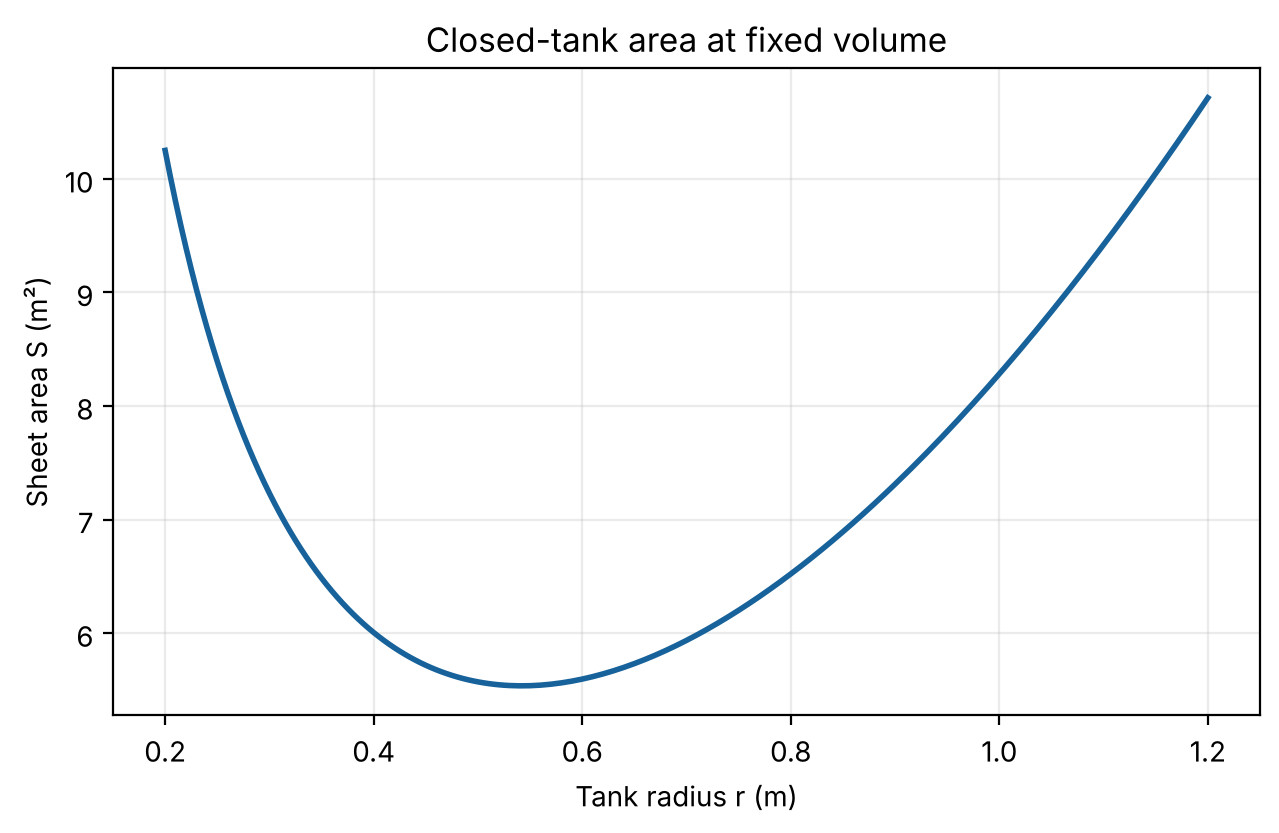

In [4]:
# Make 201 radii spanning the chosen interval, including both endpoints.
plot_radii = np.linspace(0.20, 1.20, 201)
# Start an empty Python list for the material area at each plotted radius.
plot_areas = []
# Evaluate the same validated objective for each radius on the horizontal axis.
for radius in plot_radii:
    # Append one area in m²; the list order matches the radius array order.
    plot_areas.append(surface_area(target_volume, radius))
# Convert the list to a NumPy array for convenient plotting and later checks.
plot_areas = np.array(plot_areas)
# Create axes for a single objective-function figure.
fig, ax = plt.subplots()
# Draw area against radius so both competing geometric contributions are visible.
ax.plot(plot_radii, plot_areas, color='#17629a', linewidth=2)
# Label each axis with its quantity and physical unit.
ax.set(xlabel='Tank radius r (m)', ylabel='Sheet area S (m²)', title='Closed-tank area at fixed volume')
# Add a light grid to support approximate reading of the minimum.
ax.grid(alpha=0.25)
# Show the finished figure below this cell.
plt.show()

**Reading the graph.** The left branch rises because a narrow tank must be tall, increasing its curved-wall area. The right branch rises because the two circular ends grow. Read approximate coordinates from the plot, then use a search algorithm to obtain a reproducible numerical answer.

## 3. Search with `for`, `if`, and a running best value

A **grid search** tests a finite list of radii and remembers the best one. We start at 0.20 m and add 0.02 m for each index. The `range(51)` indices are 0 through 50, so the last radius is $0.20+50(0.02)=1.20$ m. A smaller step checks more candidates but costs more objective evaluations.

We initialize `best_area` to positive infinity so the first valid candidate must improve it. `best_radius` starts as `None` to mark that no candidate has yet been selected. This loop is explicit so you can trace every update; a library call such as `min` would hide the decision process at this stage.

In [5]:
# Define the start of the allowed search interval in metres.
grid_start = 0.20
# Define the distance between neighbouring candidate radii in metres.
grid_step = 0.02
# Record that the algorithm has not yet selected any candidate.
best_radius = None
# Set a value higher than every finite area so the first comparison succeeds.
best_area = math.inf
# Keep candidate (radius, area) tuples for inspection after the search.
grid_results = []
# Visit indices 0 through 50 to examine 51 radii including 1.20 m.
for index in range(51):
    # Convert the integer index to a physical candidate radius.
    candidate_radius = grid_start + index * grid_step
    # Evaluate the sheet area for this candidate while holding volume fixed.
    candidate_area = surface_area(target_volume, candidate_radius)
    # Save the evaluated design as a tuple without changing the best result.
    grid_results.append((candidate_radius, candidate_area))
    # Compare the new area with the smallest area seen so far.
    if candidate_area < best_area:
        # Replace the best area because this candidate uses less material.
        best_area = candidate_area
        # Keep the matching radius; an area alone would not specify a design.
        best_radius = candidate_radius
# Report the chosen design and the number of objective evaluations.
print(f'Grid best: r={best_radius:.4f} m, h={height_for_radius(target_volume, best_radius):.4f} m, S={best_area:.6f} m²')
# Count the list entries rather than assuming that range supplied the expected count.
print('Candidate evaluations:', len(grid_results))
# Check that the best value really is no larger than every stored candidate area.
assert all(best_area <= area + check_tolerance for radius, area in grid_results)
# Check the first and last radii to detect a common off-by-one error.
assert math.isclose(grid_results[0][0], 0.20) and math.isclose(grid_results[-1][0], 1.20)

Grid best: r=0.5400 m, h=1.0916 m, S=5.535881 m²
Candidate evaluations: 51


**Checkpoint.** The coarse grid chooses $r=0.54$ m. It has examined 51 candidates; it has not proved that exactly 0.54 m is the mathematical optimum. Notice the different jobs of a list (`grid_results`), a tuple (one radius-area pair), a Boolean comparison (`candidate_area < best_area`), and the two variables that hold the current best design.

### Put the search in a reusable function

Refining a search means repeating the same algorithm on a narrower interval. A function avoids copying the loop and accidentally changing one copy differently. Its preconditions state that the volume and interval must be physical and that at least two candidate points are needed. It returns a tuple: best radius, best area, and number of evaluations.

In [6]:
# Package grid search into a function that can be called at different resolutions.
def grid_search(volume, lower, upper, count):
    # Describe the meaning and order of the three returned values.
    """Return (best_radius, best_area, evaluations) on a closed radius grid."""
    # Require an integer number of grid points, not a float or Boolean.
    if isinstance(count, bool) or not isinstance(count, (int, np.integer)) or count < 2:
        # Explain that both interval endpoints need grid points.
        raise ValueError('count must be an integer of at least 2')
    # Reject non-finite limits, non-positive radii, and reversed intervals.
    if not math.isfinite(lower) or not math.isfinite(upper) or lower <= 0.0 or upper <= lower:
        # Report the required interval before constructing any candidates.
        raise ValueError('require finite radii with 0 < lower < upper')
    # Validate volume once by applying the already checked geometry routine.
    height_for_radius(volume, lower)
    # Use a None sentinel to represent the absence of a selected design.
    chosen_radius = None
    # Set the starting area higher than all feasible evaluated areas.
    chosen_area = math.inf
    # Visit every integer index including the last endpoint at count - 1.
    for index in range(count):
        # Interpolate uniformly between the two bounds without accumulating step error.
        radius = lower + (upper - lower) * index / (count - 1)
        # Evaluate the same physical objective at this candidate radius.
        area = surface_area(volume, radius)
        # Update only when the new candidate uses less sheet material.
        if area < chosen_area:
            # Preserve the new smallest area for the next comparison.
            chosen_area = area
            # Preserve the matching radius for the final design.
            chosen_radius = radius
    # Return the result and the exact number of evaluations made by the loop.
    return chosen_radius, chosen_area, count

# Search a window extending one coarse step on either side of the coarse winner.
fine_radius, fine_area, fine_evaluations = grid_search(target_volume, best_radius - grid_step, best_radius + grid_step, 81)
# Display the refined radius and area with enough digits to see improvement.
print(f'Refined grid: r={fine_radius:.6f} m, S={fine_area:.9f} m² from {fine_evaluations} candidates')
# Check that the refined candidate cannot be worse than the coarse candidate inside its interval.
assert fine_area <= best_area + check_tolerance

Refined grid: r=0.542000 m, S=5.535810549 m² from 81 candidates


The refined grid tests 81 points between 0.52 and 0.56 m; neighbouring radii are 0.0005 m apart. The coarse winner lies on that grid, so refinement cannot give a *larger* best area. That statement depends on how we chose the new grid and should not be assumed for arbitrary changes of search interval.

## 4. Check the numerical result against an analytical answer

For this idealized objective, calculus supplies an independent answer. Differentiate the reduced area function:

$$\frac{dS}{dr}=4\pi r-\frac{2V}{r^2}.$$

Setting this derivative to zero gives $r_*^3=V/(2\pi)$, or

$$r_* = \left(\frac{V}{2\pi}\right)^{1/3},\qquad h_*=2r_*.$$

For $r>0$, $d^2S/dr^2=4\pi+4V/r^3>0$, so this stationary point is the unique global minimum of the *unconstrained idealized model*. Since $S(r)$ grows without bound as $r\to0^+$ and $r\to\infty$, this check also addresses radii outside our original plot. The optimum has height equal to its diameter. It does **not** automatically remain feasible when a maximum height or a list of manufactured sizes is imposed.

In [7]:
# Calculate the exact optimum radius of the idealized, unconstrained model.
analytic_radius = (target_volume / (2.0 * math.pi)) ** (1.0 / 3.0)
# Evaluate its height using the same volume relation as every other design.
analytic_height = height_for_radius(target_volume, analytic_radius)
# Evaluate its area for a common basis of comparison.
analytic_area = surface_area(target_volume, analytic_radius)
# Measure the absolute radius discrepancy of the first grid search.
coarse_error = abs(best_radius - analytic_radius)
# Measure the absolute radius discrepancy after refinement.
fine_error = abs(fine_radius - analytic_radius)
# Display the physical result and the two numerical errors.
print(f'Analytical: r={analytic_radius:.9f} m, h={analytic_height:.9f} m, S={analytic_area:.9f} m²')
# Display errors in metres rather than calling area difference a radius error.
print(f'Radius errors: coarse={coarse_error:.6f} m; refined={fine_error:.6f} m')
# Check the geometric statement that optimal height equals diameter.
assert math.isclose(analytic_height, 2.0 * analytic_radius, abs_tol=check_tolerance)
# Check the refined grid is closer in this particular constructed example.
assert fine_error < coarse_error
# Check that no grid design beats the global idealized optimum.
assert analytic_area <= fine_area + check_tolerance

Analytical: r=0.541926070 m, h=1.083852140 m, S=5.535810446 m²
Radius errors: coarse=0.001926 m; refined=0.000074 m


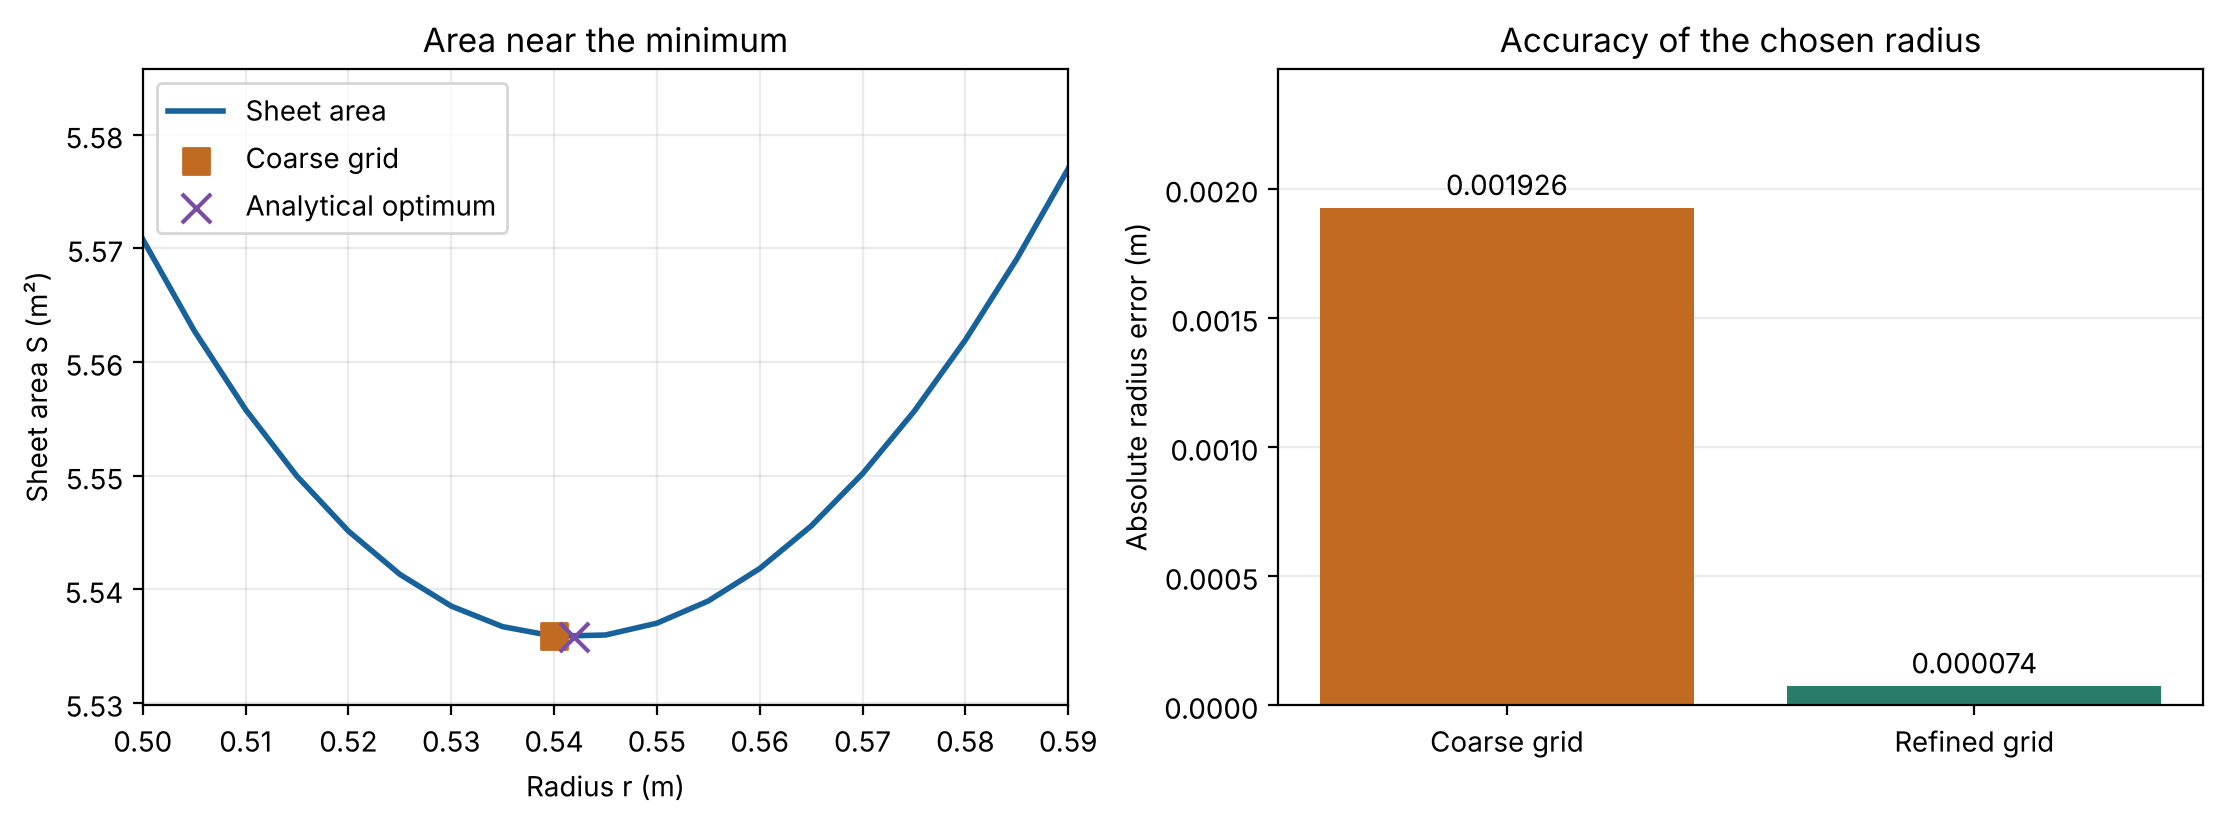

In [8]:
# Create two panels: one for the objective shape and one for radius accuracy.
fig, (curve_ax, error_ax) = plt.subplots(1, 2, figsize=(11.0, 4.0), constrained_layout=True)
# Draw the area function in a neighbourhood of its minimum.
curve_ax.plot(plot_radii, plot_areas, color='#17629a', linewidth=2, label='Sheet area')
# Mark the coarse winner to show its position on the area curve.
curve_ax.scatter([best_radius], [best_area], s=90, color='#c06a22', marker='s', zorder=3, label='Coarse grid')
# Mark the exact optimum; the refined radius is very close at this scale.
curve_ax.scatter([analytic_radius], [analytic_area], s=110, color='#7b4ca5', marker='x', zorder=5, label='Analytical optimum')
# Zoom near the minimum while retaining enough of the curve to see its shape.
curve_ax.set(xlim=(0.50, 0.59), ylim=(analytic_area - 0.006, analytic_area + 0.05), xlabel='Radius r (m)', ylabel='Sheet area S (m²)', title='Area near the minimum')
# Add a light grid for approximate reading of the area curve.
curve_ax.grid(alpha=0.25)
# Match the two visible markers to their numerical and analytical designs.
curve_ax.legend()
# Put the two measured radius errors into one list in coarse-to-fine order.
comparison_errors = [coarse_error, fine_error]
# Draw the errors separately because the refined point overlaps the optimum on the curve.
error_ax.bar(['Coarse grid', 'Refined grid'], comparison_errors, color=['#c06a22', '#287d68'])
# Label the comparison as radius error rather than the much smaller area difference.
error_ax.set(ylabel='Absolute radius error (m)', title='Accuracy of the chosen radius', ylim=(0.0, 1.28 * coarse_error))
# Visit each bar so its measured value can be printed above it.
for index, radius_error in enumerate(comparison_errors):
    # Show six decimal places to distinguish the two numerical estimates.
    error_ax.text(index, radius_error + 0.00005, f'{radius_error:.6f}', ha='center')
# Put the horizontal guide lines behind the coloured bars.
error_ax.set_axisbelow(True)
# Draw light horizontal guides to compare the measured error heights.
error_ax.grid(axis='y', alpha=0.25)
# Render both explanations as one figure within the notebook.
plt.show()

**Interpretation.** The area curve is fairly flat close to its minimum. A small difference in area need not mean a small difference in radius. We therefore report both the design variable and the objective, and we do not infer more significant digits than the search resolution supports.

## 5. How many evaluations does a finer grid require?

The loop in `grid_search` evaluates the objective exactly `count` times, so its **number of candidate evaluations grows as $O(N)$** when $N$ is the number of grid points. This statement counts objective calls; real elapsed time depends on the computer and implementation. A finer grid generally reduces the maximum possible radius spacing error when the true optimum lies inside the interval, but observed errors need not decrease monotonically: a coarse grid can happen to land unusually close to the optimum.

N= 11, step=0.100000 m, r=0.500000 m, error=0.041926 m
N= 21, step=0.050000 m, r=0.550000 m, error=0.008074 m
N= 51, step=0.020000 m, r=0.540000 m, error=0.001926 m
N=101, step=0.010000 m, r=0.540000 m, error=0.001926 m
N=501, step=0.002000 m, r=0.542000 m, error=0.000074 m


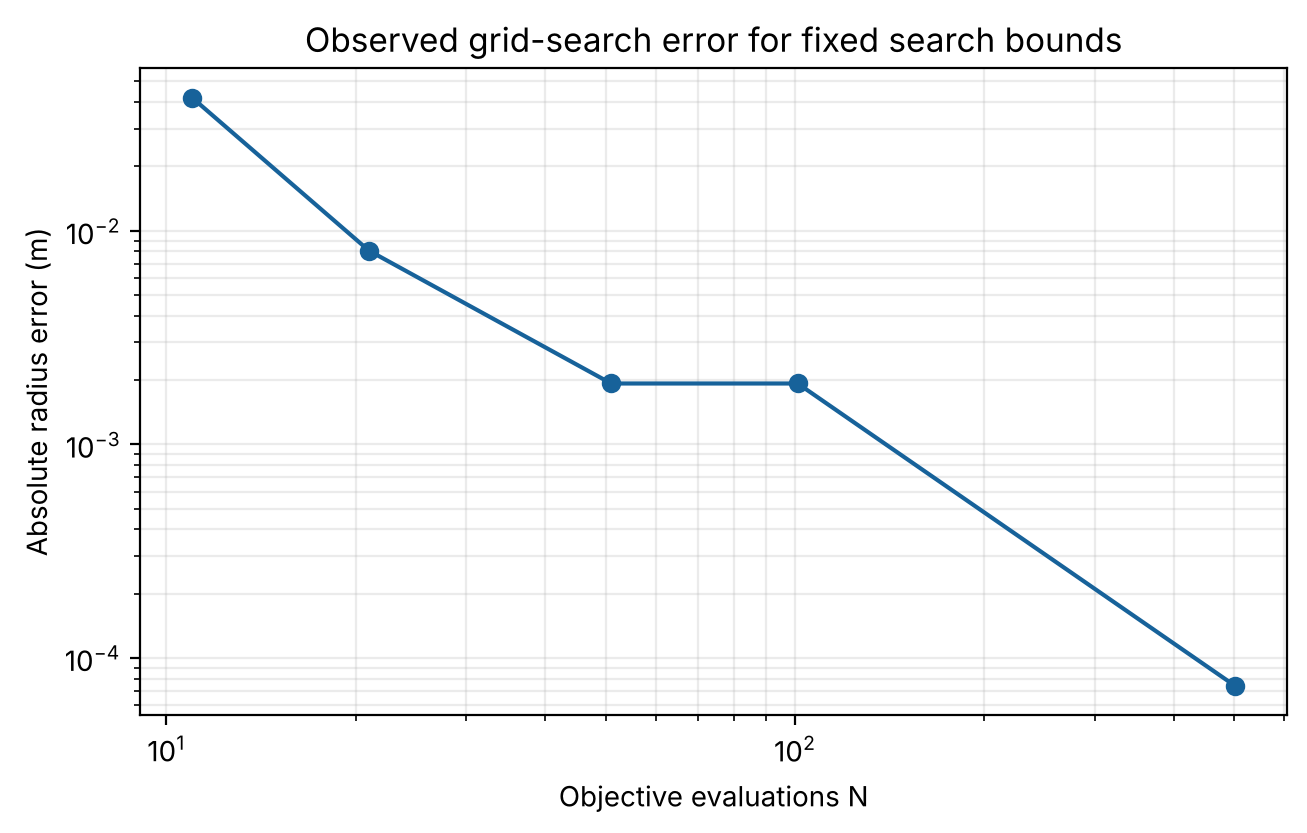

In [9]:
# Choose several grid sizes over the same fixed interval for a fair comparison.
grid_sizes = [11, 21, 51, 101, 501]
# Prepare a list to hold each observed radius error.
radius_errors = []
# Process each grid resolution with the reusable function.
for point_count in grid_sizes:
    # Solve the same design problem between 0.20 and 1.20 m.
    estimated_radius, estimated_area, evaluations = grid_search(target_volume, 0.20, 1.20, point_count)
    # Measure error against the independent analytical reference.
    radius_error = abs(estimated_radius - analytic_radius)
    # Preserve errors in the same order as the list of grid sizes.
    radius_errors.append(radius_error)
    # Report grid spacing, radius, error, and the count of objective calls.
    print(f'N={evaluations:3d}, step={1.0/(evaluations-1):.6f} m, r={estimated_radius:.6f} m, error={radius_error:.6f} m')
# Check that the reported work count equals the requested grid size for each run.
assert len(radius_errors) == len(grid_sizes)

# Open a figure to compare numerical error with the number of tested designs.
fig, ax = plt.subplots()
# Plot positive radius errors against evaluation counts on logarithmic axes.
ax.loglog(grid_sizes, radius_errors, 'o-', color='#17629a')
# Label the measured quantity on each axis and state its unit.
ax.set(xlabel='Objective evaluations N', ylabel='Absolute radius error (m)', title='Observed grid-search error for fixed search bounds')
# Add a grid on both major and minor log ticks to support reading the trend.
ax.grid(alpha=0.25, which='both')
# Render the figure without interpreting it as a universal convergence law.
plt.show()

**Pause and predict.** Doubling the number of grid points roughly halves the spacing when the interval is fixed, but it does not force the observed error to halve on every run. Explain the difference between a bound based on spacing and a particular measured error. The graph is about the **accuracy of the chosen radius**; the objective area can be much less sensitive near a flat minimum.

## 6. Practical constraints: height and available radii

Suppose the tank must be at most 1.00 m tall, and a workshop offers radii of 0.45, 0.50, 0.55, 0.60, 0.65, and 0.70 m. An available radius is **feasible** only if the height required for the fixed volume is at most 1.00 m. First filter by feasibility, then compare areas among the remaining designs. The analytical optimum of the unconstrained problem is only a reference; this finite constrained choice is a different optimization problem.

We use a list of dictionaries so each evaluated candidate carries its radius, height, area, and feasibility together. This keeps related values under descriptive keys rather than parallel lists whose indices could become misaligned.

In [10]:
# Record the manufactured radii that can actually be ordered, in metres.
available_radii = [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
# Set the maximum permitted tank height in metres.
height_limit = 1.00
# Find the smallest continuous radius that meets the height limit at fixed volume.
height_feasible_radius = math.sqrt(target_volume / (math.pi * height_limit))
# Collect all evaluated designs, including infeasible ones, for diagnosis.
available_designs = []
# Mark that no feasible manufactured design has yet been found.
selected_design = None
# Visit every manufactured radius once so no available design is overlooked.
for radius in available_radii:
    # Compute the height that satisfies the fixed-volume requirement.
    height = height_for_radius(target_volume, radius)
    # Compute sheet area using the same objective as earlier.
    area = surface_area(target_volume, radius)
    # Test the height constraint; equality is allowed by the stated rule.
    feasible = height <= height_limit
    # Group the candidate's physical measurements and decision in one dictionary.
    design = {'radius': radius, 'height': height, 'area': area, 'feasible': feasible}
    # Save the candidate for a complete record, whether accepted or rejected.
    available_designs.append(design)
    # Consider only physically and practically feasible candidates for selection.
    if feasible:
        # Select the first feasible design or replace a more material-intensive one.
        if selected_design is None or area < selected_design['area']:
            # Keep the entire dictionary so height and area stay paired with radius.
            selected_design = design
# Reject a situation where the feasible set is empty instead of using None as a design.
if selected_design is None:
    # Explain why no optimum can be reported under these constraints.
    raise ValueError('no available radius satisfies the height limit')
# Print a small table that makes the feasibility decision visible.
for design in available_designs:
    # Print one row with units and a clear yes/no decision.
    print(f"r={design['radius']:.2f} m | h={design['height']:.3f} m | S={design['area']:.4f} m² | feasible={design['feasible']}")
# Report the lowest-area choice from the feasible manufactured sizes.
print('Selected constrained design:', selected_design)
# Check the expected manufactured radius for this stated limit and list.
assert math.isclose(selected_design['radius'], 0.60, abs_tol=check_tolerance)
# Independently check that the selected design meets its height limit.
assert selected_design['height'] <= height_limit
# Confirm that the continuous height boundary is to the right of the unconstrained optimum.
assert height_feasible_radius > analytic_radius

r=0.45 m | h=1.572 m | S=5.7168 m² | feasible=False
r=0.50 m | h=1.273 m | S=5.5708 m² | feasible=False
r=0.55 m | h=1.052 m | S=5.5370 m² | feasible=False
r=0.60 m | h=0.884 m | S=5.5953 m² | feasible=True
r=0.65 m | h=0.753 m | S=5.7316 m² | feasible=True
r=0.70 m | h=0.650 m | S=5.9359 m² | feasible=True
Selected constrained design: {'radius': 0.6, 'height': 0.8841941282883075, 'area': 5.595280043917985, 'feasible': True}


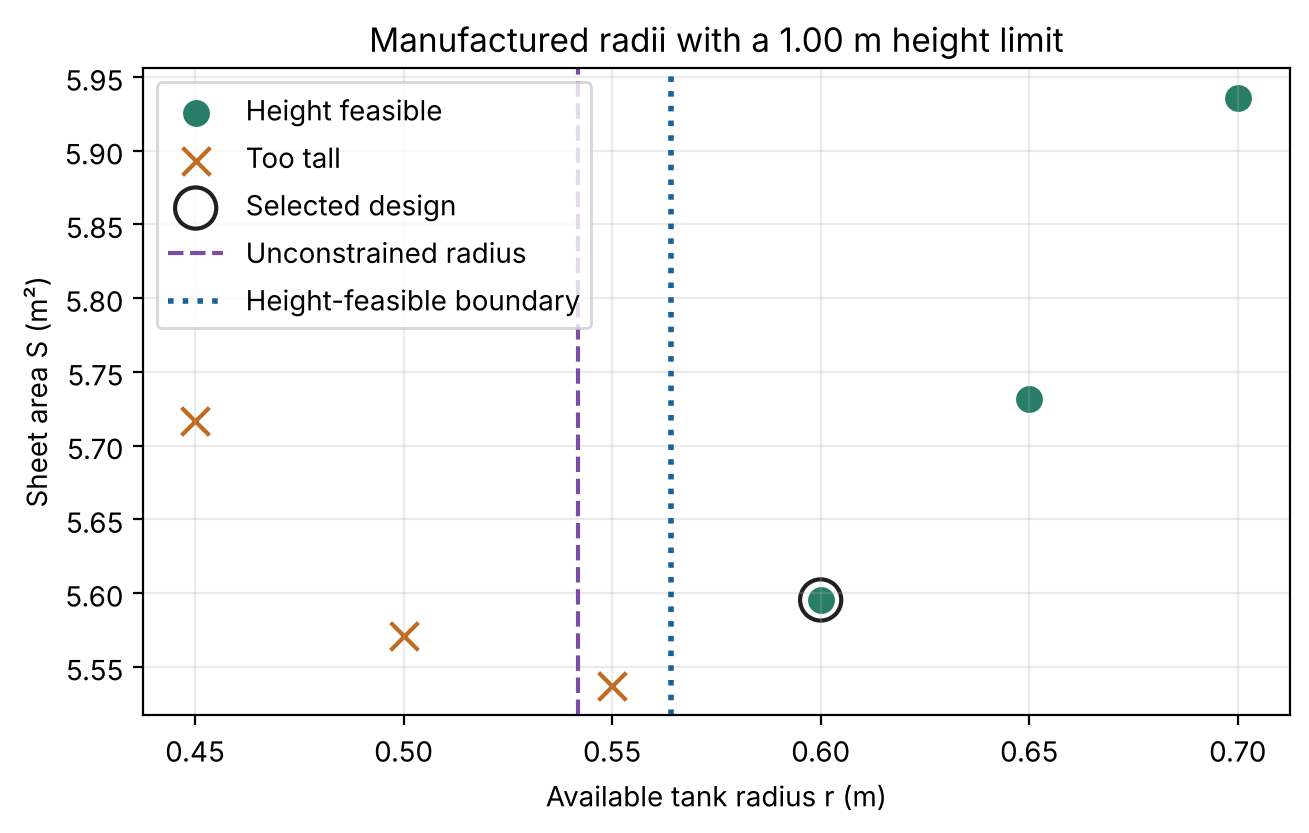

In [11]:
# Split candidates by the Boolean feasibility flag for a clear plot legend.
feasible_designs = [design for design in available_designs if design['feasible']]
# Keep rejected candidates visible rather than silently discarding them.
rejected_designs = [design for design in available_designs if not design['feasible']]
# Create axes for the discrete constrained choices.
fig, ax = plt.subplots()
# Draw feasible manufactured radii as green points at their sheet areas.
ax.scatter([design['radius'] for design in feasible_designs], [design['area'] for design in feasible_designs], color='#287d68', s=75, label='Height feasible')
# Draw rejected radii as orange crosses to show the height restriction's effect.
ax.scatter([design['radius'] for design in rejected_designs], [design['area'] for design in rejected_designs], color='#c06a22', marker='x', s=100, label='Too tall')
# Circle the selected feasible design without replacing its original point.
ax.scatter([selected_design['radius']], [selected_design['area']], facecolors='none', edgecolors='#202020', s=220, linewidths=1.5, label='Selected design')
# Mark the continuous unconstrained answer only as a comparison reference.
ax.axvline(analytic_radius, color='#7b4ca5', linestyle='--', label='Unconstrained radius')
# Mark where continuous radii first become short enough to meet the height limit.
ax.axvline(height_feasible_radius, color='#17629a', linestyle=':', linewidth=2, label='Height-feasible boundary')
# Describe the two quantities and the actual constrained design question.
ax.set(xlabel='Available tank radius r (m)', ylabel='Sheet area S (m²)', title='Manufactured radii with a 1.00 m height limit')
# Add a light grid and labels for the four kinds of marks.
ax.grid(alpha=0.25)
# Place the legend where it does not hide the selected or rejected designs.
ax.legend(loc='upper left')
# Display the discrete design comparison below the cell.
plt.show()

**Interpretation.** At 0.55 m, the height is still above 1.00 m. The height limit requires a continuous radius of at least about 0.564 m. Because this boundary lies to the right of the unconstrained minimum and area increases beyond that minimum, 0.564 m would be the optimum *if every radius were available*. Among manufactured sizes, 0.60 m is the first feasible choice and has less area than the larger feasible choices. If none were feasible, the code would stop with a clear exception rather than claim an optimum.

## 7. Optional: narrow an interval with golden-section search

Grid search evaluates every listed candidate. A different algorithm can exploit the fact that the idealized area $S(r)$ decreases and then increases on a positive interval containing its minimum. **Golden-section search** keeps a bracket $[a,b]$ around that minimum, compares two interior radii, discards a part of the bracket, and reuses one of the previous area evaluations. It needs the **unimodal** shape shown earlier; it is not a generic method for arbitrary objectives with several local minima.

Let $q=(\sqrt5-1)/2\approx0.618$. At each step choose $c=b-q(b-a)$ and $d=a+q(b-a)$, with $a<c<d<b$. If $S(c)\le S(d)$, the minimum cannot lie strictly to the right of $d$, so update $b=d$; otherwise update $a=c$. Stop when the bracket width is below a specified tolerance. This demonstrates a bounded `while` loop, state updates, a stopping rule, and the benefit of reusing a computed value. The returned radius is the midpoint of a narrow bracket, **not** a proof that any arbitrary objective has been globally minimized.

In [12]:
# Define a bounded interval-narrowing search for this one-dimensional tank objective.
def golden_section_search(volume, lower, upper, width_tolerance=1e-7, max_steps=100):
    # Document the returned radius, area, iteration count, call count, and widths.
    """Return (radius, area, steps, evaluations, widths) for a unimodal bracket."""
    # Require positive ordered bounds and finite physical inputs.
    if not math.isfinite(lower) or not math.isfinite(upper) or lower <= 0.0 or upper <= lower:
        # Explain that both bracket endpoints must be positive, finite, and ordered.
        raise ValueError('require finite radii with 0 < lower < upper')
    # Use the validated geometry function to reject non-physical volume.
    height_for_radius(volume, lower)
    # Reject tolerances that would never make a meaningful width test.
    if not math.isfinite(width_tolerance) or width_tolerance <= 0.0:
        # State that a finite positive width is needed for a usable stopping test.
        raise ValueError('width_tolerance must be finite and positive')
    # Require an integer cap so the while loop cannot run indefinitely.
    if isinstance(max_steps, bool) or not isinstance(max_steps, int) or max_steps < 1:
        # Report a violated step-cap contract before the first iteration.
        raise ValueError('max_steps must be a positive integer')
    # Store the golden ratio's shorter segment fraction, about 0.618.
    q = (math.sqrt(5.0) - 1.0) / 2.0
    # Choose the first interior radius, closer to the left bracket end.
    c = upper - q * (upper - lower)
    # Choose the second interior radius, closer to the right bracket end.
    d = lower + q * (upper - lower)
    # Evaluate the left interior candidate once before comparing both sides.
    area_c = surface_area(volume, c)
    # Evaluate the right interior candidate once before the first bracket update.
    area_d = surface_area(volume, d)
    # Count the two objective evaluations performed before the loop.
    evaluations = 2
    # Start the iteration count at zero before any bracket update.
    steps = 0
    # Record the initial bracket width for a convergence plot.
    widths = [upper - lower]
    # Continue while more precision is requested and the work cap permits it.
    while upper - lower > width_tolerance and steps < max_steps:
        # Compare two already evaluated radii to select a retained interval.
        if area_c <= area_d:
            # Discard the part strictly to the right of d.
            upper = d
            # Reuse the old left interior radius as the new right interior one.
            d = c
            # Reuse its area instead of calling the objective again.
            area_d = area_c
            # Place one new radius inside the shortened bracket.
            c = upper - q * (upper - lower)
            # Evaluate only the new radius in this branch.
            area_c = surface_area(volume, c)
        # Handle the case where the right interior design has less area.
        else:
            # Discard the part strictly to the left of c.
            lower = c
            # Reuse the old right interior radius as the new left interior one.
            c = d
            # Reuse its area instead of calling the objective again.
            area_c = area_d
            # Place one new radius inside the shortened bracket.
            d = lower + q * (upper - lower)
            # Evaluate only the new radius in this branch.
            area_d = surface_area(volume, d)
        # Account for the one new objective evaluation in either branch.
        evaluations += 1
        # Count a completed update so the work cap remains effective.
        steps += 1
        # Save the new width to examine how quickly the interval shrinks.
        widths.append(upper - lower)
    # Detect a run stopped by max_steps rather than by the requested width.
    if upper - lower > width_tolerance:
        # Signal that the requested precision was not attained.
        raise RuntimeError('bracket did not reach the requested width')
    # Estimate the optimum by the centre of the remaining narrow bracket.
    midpoint = (lower + upper) / 2.0
    # Evaluate the reported design's area; it was not necessarily a test point.
    midpoint_area = surface_area(volume, midpoint)
    # Include this final evaluation in the reported objective-call count.
    evaluations += 1
    # Return the design, its objective, work counts, and convergence history.
    return midpoint, midpoint_area, steps, evaluations, widths

# Search the same positive interval used for the full objective plot.
golden_radius, golden_area, golden_steps, golden_calls, bracket_widths = golden_section_search(target_volume, 0.20, 1.20)
# Display both design variables and the two measures of algorithm work.
print(f'Golden section: r={golden_radius:.9f} m, S={golden_area:.9f} m²; steps={golden_steps}, objective calls={golden_calls}')
# Verify the returned radius against the independently derived analytical result.
assert abs(golden_radius - analytic_radius) < 1e-7
# Verify that the saved history records one width per initial state and update.
assert len(bracket_widths) == golden_steps + 1

Golden section: r=0.541926056 m, S=5.535810446 m²; steps=34, objective calls=37


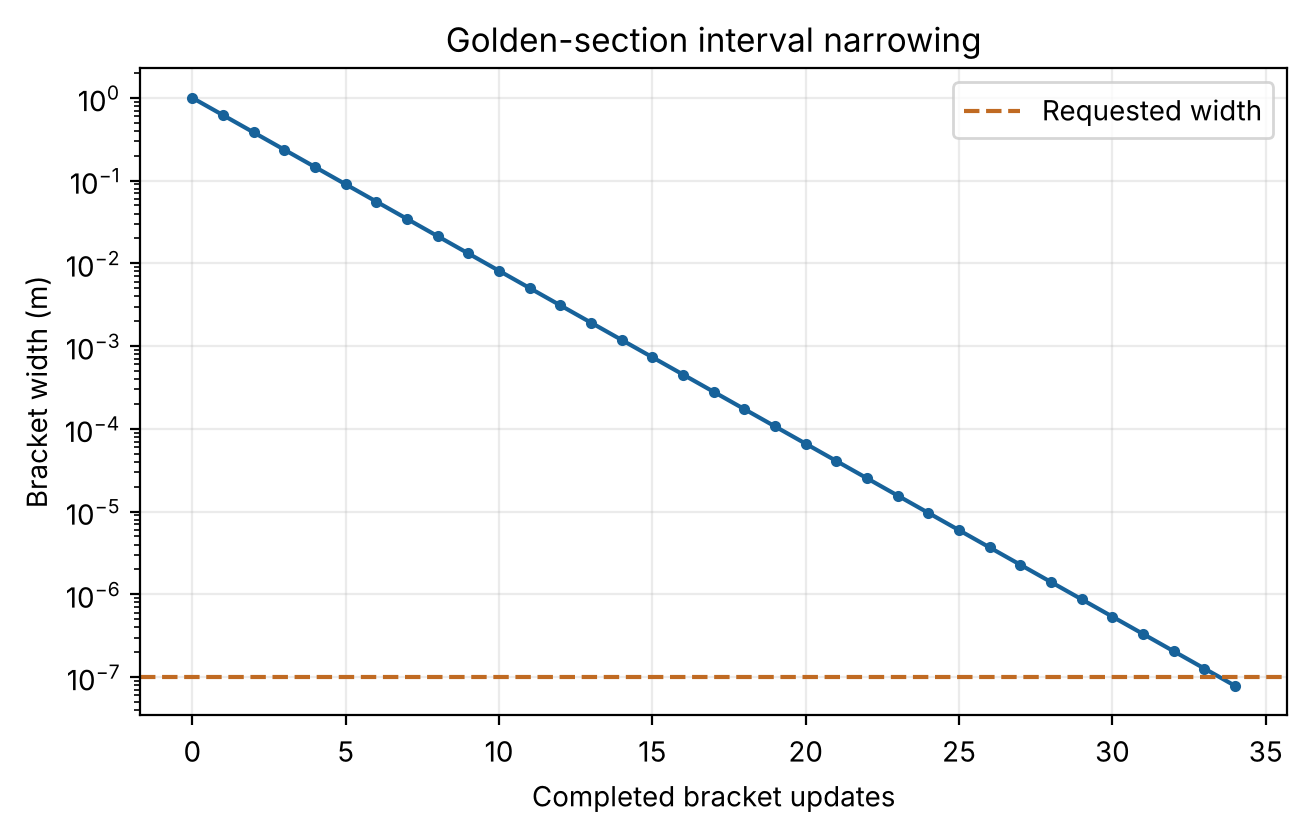

In [13]:
# Number the initial bracket as step zero and each update thereafter.
step_numbers = np.arange(len(bracket_widths))
# Open axes for the convergence history of the interval width.
fig, ax = plt.subplots()
# Show multiplicative narrowing clearly with a logarithmic vertical axis.
ax.semilogy(step_numbers, bracket_widths, 'o-', markersize=3, color='#17629a')
# Mark the requested stopping width to connect the plot with the while condition.
ax.axhline(1e-7, color='#c06a22', linestyle='--', label='Requested width')
# State that the diagnostic is bracket width, not exact radius error.
ax.set(xlabel='Completed bracket updates', ylabel='Bracket width (m)', title='Golden-section interval narrowing')
# Add a light grid for reading orders of magnitude.
ax.grid(alpha=0.25)
# Label the threshold line without obscuring the observed history.
ax.legend()
# Render the convergence figure below this cell.
plt.show()

**Interpretation.** The vertical axis shows bracket width, not an observed error measured against the analytical solution. For a single interior optimum kept inside the bracket, the midpoint's radius error is at most half the final width. This method uses far fewer evaluations than a uniform grid spaced at $10^{-7}$ m across a one-metre interval. That comparison is about **objective-call counts**, not a timing guarantee. The discrete manufactured-size problem still requires checking which listed designs meet its constraints.

## 8. Optional: represent one design as an object

Classes are the subject of notebook 10; this section is a preview. Here a tank design has a volume and radius as its state; `height()` and `area()` are methods that operate on that state. A class becomes useful if a larger program must pass designs among many functions or store several competing designs. It is not needed for the first grid search, where simple values make the algorithm easy to trace.

In [14]:
# Define an object that groups one tank's fixed volume and chosen radius.
class TankDesign:
    # Initialize a new instance from two physical quantities.
    def __init__(self, volume, radius):
        # Validate inputs with the existing geometry function before storing them.
        height_for_radius(volume, radius)
        # Save the validated capacity as an instance attribute in cubic metres.
        self.volume = float(volume)
        # Save the chosen radius as an instance attribute in metres.
        self.radius = float(radius)

    # Provide a method that derives height from this object's current state.
    def height(self):
        # Reuse the tested geometry rule rather than copy its formula into the class.
        return height_for_radius(self.volume, self.radius)

    # Provide a method that evaluates sheet area for this design.
    def area(self):
        # Reuse the same tested objective used in all search algorithms.
        return surface_area(self.volume, self.radius)

    # Define a readable representation for an instance printed in a notebook.
    def __str__(self):
        # Include radius, derived height, and area with their physical units.
        return f'Tank(r={self.radius:.3f} m, h={self.height():.3f} m, S={self.area():.4f} m²)'

# Create one object for the best feasible manufactured radius.
chosen_tank = TankDesign(target_volume, selected_design['radius'])
# Call __str__ through print to show the design's state in physical units.
print(chosen_tank)
# Check that its methods agree with the earlier dictionary-based evaluation.
assert math.isclose(chosen_tank.area(), selected_design['area'], abs_tol=check_tolerance)

Tank(r=0.600 m, h=0.884 m, S=5.5953 m²)


## 9. Tests, assumptions, and sources of error

A trustworthy result needs several kinds of checks:

| Check | What it detects | What it cannot establish |
|:--|:--|:--|
| Reconstructed volume $\pi r^2h=V$ | Wrong height equation or inconsistent units | Whether a cylinder is the right physical model |
| Independent analytical minimum | Search mistakes for the idealized continuous objective | The best constrained, manufactured design |
| Several grid resolutions | Sensitivity to search spacing | Accuracy outside the chosen interval |
| Invalid-input tests | Missing validation for common bad inputs | Every possible programming error |
| Constraint table | Which listed designs satisfy the stated height limit | Unmodeled manufacturing or safety requirements |

**Numerical error** arises because a finite grid samples only selected radii. **Model error** arises when real tanks depart from our idealized thin-sheet geometry or cost assumptions. Neither is repaired by displaying more decimal places. The code below tests three invalid inputs and confirms that the expected errors are raised clearly.

In [15]:
# Prepare named invalid calls so the self-study checks are easy to identify.
invalid_calls = [('zero radius', surface_area, (1.0, 0.0)), ('negative volume', height_for_radius, (-1.0, 0.5)), ('one grid point', grid_search, (1.0, 0.2, 1.2, 1))]
# Try each deliberately invalid call without stopping Run All on an expected error.
for label, function, arguments in invalid_calls:
    # Enter an exception handler for the one case under examination.
    try:
        # Unpack the tuple of arguments into the named function.
        function(*arguments)
    # Handle only the ValueError promised by the input checks.
    except ValueError as error:
        # Show both the case name and the explanatory message.
        print(f'{label}: expected error: {error}')
    # Mark silent acceptance as a failed validation check.
    else:
        # Stop the notebook if a nonphysical input produced a result.
        raise AssertionError(f'{label} was not rejected')

zero radius: expected error: volume and radius must be finite positive numbers
negative volume: expected error: volume and radius must be finite positive numbers
one grid point: expected error: count must be an integer of at least 2


## 10. Independent practice

Try these in a new cell before running the answer cell. State units whenever you report a physical quantity.

1. For $V=2\,\mathrm{m^3}$ and $r=1\,\mathrm m$, calculate $h$ and $S$ using the two functions. Reconstruct the volume.
2. What is the first radius visited by `range(5)` with `lower=0.20`, `upper=1.20`, and `count=5`? What is the last? What spacing does `grid_search` use?
3. Use `grid_search(1.0, 0.20, 1.20, 5)`. Which candidate wins? Explain why its radius differs from the analytical answer.
4. Derive the analytical optimum for $V=2\,\mathrm{m^3}$ from $r_*^3=V/(2\pi)$. By what factor does the optimum radius change when volume doubles?
5. Find the minimum allowed radius imposed solely by $h\le1.00$ m for $V=1.00\,\mathrm{m^3}$. Explain why 0.55 m is too small.
6. Change the manufactured list to `[0.45, 0.50, 0.55]` without changing the height limit. What should a robust selection routine report?
7. Explain why replacing `candidate_area < best_area` with `candidate_area > best_area` changes the question the grid loop answers. How would the initial value of `best_area` also have to change to search for a maximum?

Read the answer cell only after making predictions. Answers 2–3 depend on the exact finite grid; answers 4–5 concern the continuous mathematical model.

In [16]:
# Calculate the height for the first practice design at volume two and radius one.
exercise_height = height_for_radius(2.0, 1.0)
# Calculate the corresponding closed-cylinder area in square metres.
exercise_area = surface_area(2.0, 1.0)
# Run a five-point coarse grid over the same interval as the worked example.
exercise_radius, exercise_grid_area, exercise_calls = grid_search(1.0, 0.20, 1.20, 5)
# Derive the new analytical radius from the doubled target volume.
double_volume_radius = (2.0 / (2.0 * math.pi)) ** (1.0 / 3.0)
# Rearrange the height cap into a minimum permitted radius.
minimum_height_feasible_radius = math.sqrt(1.0 / (math.pi * height_limit))
# Display both physical quantities for practice question one.
print(f'1. h={exercise_height:.6f} m; S={exercise_area:.6f} m²; reconstructed V={math.pi * 1.0**2 * exercise_height:.6f} m³')
# Display the grid endpoints, spacing, and chosen finite candidate.
print(f'2–3. Five-point grid: first=0.20 m, last=1.20 m, step=0.25 m, best={exercise_radius:.2f} m')
# Compare the analytical radii to reveal the cube-root scaling with capacity.
print(f'4. r*(V=2)={double_volume_radius:.6f} m; ratio={double_volume_radius/analytic_radius:.6f}')
# Display the continuous minimum radius required by the height limit.
print(f'5. Height cap requires r >= {minimum_height_feasible_radius:.6f} m')
# Check volume reconstruction and the five-point winner against independent calculations.
assert math.isclose(math.pi * exercise_height, 2.0, abs_tol=check_tolerance)
# Check the finite five-point candidate and its work count.
assert math.isclose(exercise_radius, 0.45, abs_tol=check_tolerance) and exercise_calls == 5
# Check the exact scaling rule for a doubled fixed volume.
assert math.isclose(double_volume_radius / analytic_radius, 2.0 ** (1.0 / 3.0), abs_tol=check_tolerance)

1. h=0.636620 m; S=10.283185 m²; reconstructed V=2.000000 m³
2–3. Five-point grid: first=0.20 m, last=1.20 m, step=0.25 m, best=0.45 m
4. r*(V=2)=0.682784 m; ratio=1.259921
5. Height cap requires r >= 0.564190 m


**Answers 6–7.** All three radii in `[0.45, 0.50, 0.55]` require a height greater than 1.00 m, so the routine should report **no feasible design** rather than invent a winner. Reversing `<` to `>` asks for a *maximum* among visited candidates; with `best_area=math.inf` no finite candidate can improve that initial value, so a maximum search would instead start at `-math.inf`. It would also answer a different engineering question.

### Closing reflection

An engineering optimizer consists of a **model**, an **objective**, a set of **constraints**, a **search algorithm**, and **checks**. We used an analytical result to assess a numerical method when one was available; many real objectives have no convenient closed-form solution. The physical assumptions and the constraints determine what a reported optimum means. The same programming pattern applies to selecting dimensions, operating conditions, and parameters in other engineering problems.